In [3]:
import json
import pandas as pd
import matplotlib.pyplot as plt 

with open("ukhsa-chart-download.json", "r") as file:
    data = json.load(file)

print(type(data))
print(data.keys() if isinstance(data, dict) else data[:2])

<class 'list'>
[{'theme': 'infectious_disease', 'sub_theme': 'respiratory', 'topic': 'Influenza', 'geography_type': 'Nation', 'geography': 'England', 'metric': 'influenza_healthcare_hospitalAdmissionRateByWeek', 'age': 'all', 'stratum': 'default', 'sex': 'all', 'year': 2026, 'date': '2026-04-20', 'metric_value': '0.2200', 'in_reporting_delay_period': False}, {'theme': 'infectious_disease', 'sub_theme': 'respiratory', 'topic': 'Influenza', 'geography_type': 'Nation', 'geography': 'England', 'metric': 'influenza_healthcare_hospitalAdmissionRateByWeek', 'age': 'all', 'stratum': 'default', 'sex': 'all', 'year': 2026, 'date': '2026-04-13', 'metric_value': '0.2200', 'in_reporting_delay_period': False}]


In [4]:
df = pd.DataFrame(data)
df.head()


,theme,sub_theme,topic,geography_type,geography,metric,age,stratum,sex,year,date,metric_value,in_reporting_delay_period
0,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2026,2026-04-20,0.2200,False
1,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2026,2026-04-13,0.2200,False
2,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2026,2026-04-06,0.3000,False
3,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2026,2026-03-30,0.2000,False
4,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2026,2026-03-23,0.3200,False


In [7]:
df["date"] = pd.to_datetime(df["date"])
df_2025 = df[df["date"].dt.year == 2025]

df_2025.head()

,theme,sub_theme,topic,geography_type,geography,metric,age,stratum,sex,year,date,metric_value,in_reporting_delay_period
67,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-06,10.9100,False
66,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-13,9.5800,False
65,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-20,7.4700,False
64,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-27,6.8800,False
63,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-02-03,5.5300,False


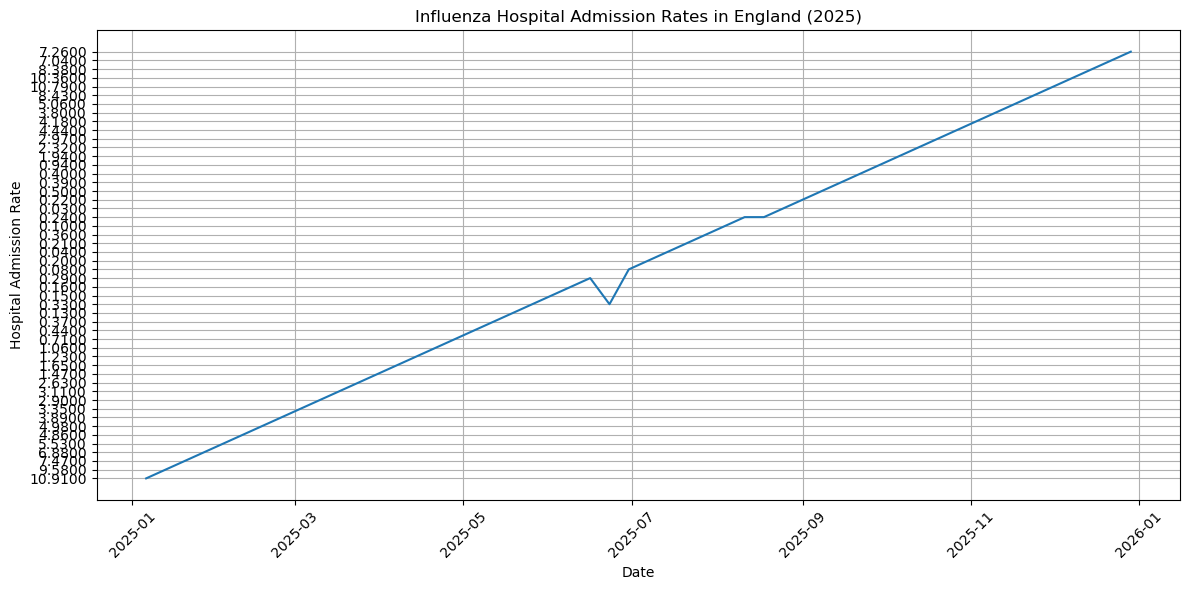

2025-01-06 00:00:00
2025-12-29 00:00:00
52


In [10]:
plt.figure(figsize=(12, 6))

plt.plot(df_2025["date"], df_2025["metric_value"])

plt.title("Influenza Hospital Admission Rates in England (2025)")
plt.xlabel("Date")
plt.ylabel("Hospital Admission Rate")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

print(df_2025["date"].min())
print(df_2025["date"].max())
print(len(df_2025))

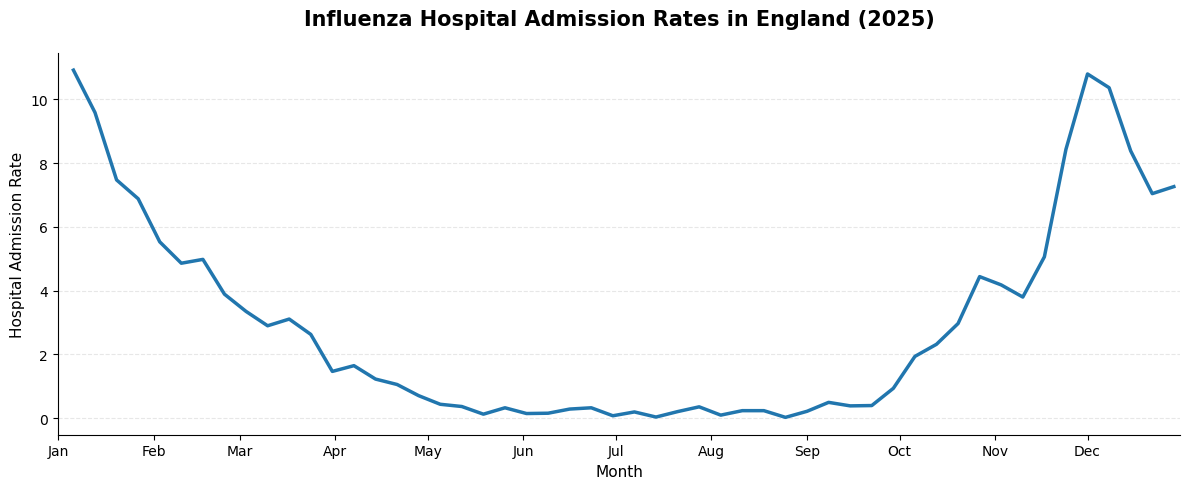

In [11]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# Filter data for 2025
df["date"] = pd.to_datetime(df["date"])

df_2025 = df[df["date"].dt.year == 2025].copy()
df_2025["metric_value"] = pd.to_numeric(
    df_2025["metric_value"], errors="coerce"
)

# Sort dates and remove missing values
df_2025 = df_2025.sort_values("date")
df_2025 = df_2025.dropna(subset=["metric_value"])

# Create graph
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df_2025["date"],
    df_2025["metric_value"],
    color="#2176AE",
    linewidth=2.5
)

# Formatting
ax.set_title(
    "Influenza Hospital Admission Rates in England (2025)",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Hospital Admission Rate", fontsize=11)

# Show months instead of every date
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Add subtle gridlines
ax.grid(axis="y", linestyle="--", alpha=0.3)

ax.set_xlim(pd.Timestamp("2025-01-01"),
            pd.Timestamp("2025-12-31"))

plt.tight_layout()
plt.show()

In [13]:
df_2025.to_pickle("influenza_2025.pkl")

In [14]:
import os 

print(os.path.exists("influenza_2025.pkl"))

True


In [15]:
influenza_data = pd.read_pickle("influenza_2025.pkl")
influenza_data.head()

,theme,sub_theme,topic,geography_type,geography,metric,age,stratum,sex,year,date,metric_value,in_reporting_delay_period
67,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-06,10.91,False
66,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-13,9.58,False
65,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-20,7.47,False
64,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-27,6.88,False
63,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-02-03,5.53,False


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

df = pd.read_pickle("influenza_2025.pkl")

df.head()

,theme,sub_theme,topic,geography_type,geography,metric,age,stratum,sex,year,date,metric_value,in_reporting_delay_period
67,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-06,10.91,False
66,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-13,9.58,False
65,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-20,7.47,False
64,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-27,6.88,False
63,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-02-03,5.53,False


In [1]:
from IPython.display import clear_output
import ipywidgets as wdg
import pandas as pd 
import matplotlib.pyplot as plt


The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [2]:
print("Python is working!")
print(pd.__version__)


Python is working!
2.3.3


In [3]:
%matplotlib inline 
plt.rcParams["figure.dpi"] = 100

df = pd.read_pickle("influenza_2025.pkl")
df.head()

,theme,sub_theme,topic,geography_type,geography,metric,age,stratum,sex,year,date,metric_value,in_reporting_delay_period
67,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-06,10.91,False
66,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-13,9.58,False
65,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-20,7.47,False
64,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-01-27,6.88,False
63,infectious_disease,respiratory,Influenza,Nation,England,influenza_healthcare_hospitalAdmissionRateByWeek,all,default,all,2025,2025-02-03,5.53,False


In [4]:
refresh_button = wdg.Button(
    description="Refresh Data",
    button_style="info",
    icon="refresh"
)

output = wdg.Output()


def refresh_data(button):
    global df

    with output:
        clear_output(wait=True)
        df = pd.read_pickle("influenza_2025.pkl")
        print("Data reloaded successfully!")
        display(df.head())


refresh_button.on_click(refresh_data)


display(refresh_button, output)

Button(button_style='info', description='Refresh Data', icon='refresh', style=ButtonStyle())

Output()

In [6]:
import matplotlib.dates as mdates


df["date"] = pd.to_datetime(df["date"])
df["metric_value"] = pd.to_numeric(df["metric_value"])


month_dropdown = wdg.Dropdown(
    options=[
        "All months", "January", "February", "March",
        "April", "May", "June", "July", "August",
        "September", "October", "November", "December"
    ],
    value="All months",
    description="Month:"
)


graph_output = wdg.Output()

def update_graph(change=None):

    with graph_output:
        clear_output(wait=True)

        
        if month_dropdown.value == "All months":
            filtered = df.copy()
        else:
            filtered = df[
                df["date"].dt.month_name() == month_dropdown.value
            ].copy()

        filtered = filtered.sort_values("date")

 
        fig, ax = plt.subplots(figsize=(11, 5))

        ax.plot(
            filtered["date"],
            filtered["metric_value"],
            color="steelblue",
            linewidth=2.5,
            marker="o"
        )

        ax.set_title("Influenza Hospital Admission Rates - 2025")
        ax.set_xlabel("Date")
        ax.set_ylabel("Hospital Admission Rate")
        ax.grid(axis="y", alpha=0.3)

        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%d %b")
        )

        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()


month_dropdown.observe(update_graph, names="value")

display(month_dropdown, graph_output)

update_graph()

Dropdown(description='Month:', options=('All months', 'January', 'February', 'March', 'April', 'May', 'June', …

Output()

In [7]:
dashboard_title = wdg.HTML(
    "<h2>Influenza Surveillance Dashboard - England 2025</h2>"
)

controls = wdg.HBox([ month_dropdown, refresh_button])

dashboard = wdg.VBox([ dashboard_title, controls, graph_output, output])

display(dashboard)

In [9]:
def refresh_dashboard(button):
    global df 

    df = pd.read_pickle("influenza_2025.pkl")
    df["date"] = pd.to_datetime(df["date"])
    df["metric_value"] = pd.to_numeric(df["metric_value"])

    update_graph()

    refresh_button.on_click(refresh_dashboard)

In [10]:

df["date"] = pd.to_datetime(df["date"])

dates = sorted(df["date"].dropna().unique())

date_slider = wdg.SelectionRangeSlider(
    options=[(pd.Timestamp(d).strftime("%d %b %Y"), d)
             for d in dates],
    index=(0, len(dates) - 1),
    description="Date range:",
    layout=wdg.Layout(width="90%"),
    continuous_update=False
)

display(date_slider)

SelectionRangeSlider(continuous_update=False, description='Date range:', index=(0, 51), layout=Layout(width='9…

In [11]:
def update_graph(change=None):

    with graph_output:
        clear_output(wait=True)

        filtered = df.copy()

        
        if month_dropdown.value != "All months":
            filtered = filtered[
                filtered["date"].dt.month_name() == month_dropdown.value
            ]

        
        start_date, end_date = date_slider.value

        filtered = filtered[
            (filtered["date"] >= start_date) &
            (filtered["date"] <= end_date)
        ]

        filtered = filtered.sort_values("date")

        fig, ax = plt.subplots(figsize=(11, 5))

        ax.plot(
            filtered["date"],
            filtered["metric_value"],
            color="steelblue",
            linewidth=2.5,
            marker="o"
        )

        ax.set_title(
            "Influenza Hospital Admission Rates - England 2025",
            fontsize=14,
            fontweight="bold"
        )

        ax.set_xlabel("Date")
        ax.set_ylabel("Hospital Admission Rate")
        ax.grid(axis="y", alpha=0.3)

        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%d %b")
        )

        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()


date_slider.observe(update_graph, names="value")
month_dropdown.observe(update_graph, names="value")

dashboard = wdg.VBox([
    dashboard_title,
    wdg.HBox([month_dropdown, refresh_button]),
    date_slider,
    graph_output,
    output
])

display(dashboard)
update_graph()